# 03 — Espaços de cores, histogramas e contraste

**EP · Data Science Knowledge Base | Análise e Classificação de Imagens | Notebook 03/16**

**Pré-requisitos:** Python, NumPy e fundamentos de visualização; consulte os capítulos anteriores quando necessário.

**Escopo de validação:** As células principais usam dados sintéticos ou conjuntos fornecidos pelas bibliotecas. Dependências adicionais só são necessárias nos laboratórios explicitamente opcionais.

---

> **Biblioteca pessoal de Ciência de Dados** · Análise e Classificação de Imagens · Capítulo 03/16

> **Execução:** ainda não confirmada nesta versão; reinicie o kernel e execute as células obrigatórias localmente.


### Materiais complementares

- [Guia Técnico](./reference_materials/03_cores_histogramas_realce.pdf)
- [Cheat Sheet](./cheat_sheets/cheat_sheet_cores_histogramas_realce.pdf)


## Como estudar este capítulo

1. Leia os fundamentos e consulte o Guia Técnico correspondente.
2. Reinicie o kernel e execute as células obrigatórias na sequência.
3. Confira tabelas, visualizações, saídas e limitações descritas no notebook.
4. Resolva o exercício antes de consultar a solução; execute laboratórios opcionais apenas em ambiente compatível.

**Pré-requisitos transversais:** Programação Python (01), visualização de dados (02), Estatística (03), Machine Learning (05) e Deep Learning (07), conforme o capítulo.


## Objetivos de aprendizagem

Comparar RGB, HSV e intensidade; avaliar equalização de histograma.

Ao concluir, você deverá ser capaz de **explicar a técnica**, **executar o exemplo**, **interpretar limitações** e **justificar escolhas de avaliação**.

## Fundamentos conceituais

Os canais RGB codificam componentes de luz; HSV organiza matiz e saturação de maneira diferente. Histogramas descrevem frequências de intensidade, mas descartam posição espacial. Equalização global pode amplificar ruído; CLAHE limita contraste local. O OpenCV carrega imagens coloridas em BGR, não RGB.

### Conceito matemático

$$h(k)=\sum_{x,y}{\bf1}[I(x,y)=k]$$

A fórmula expressa o mecanismo principal do capítulo. Identifique unidades, dimensões e hipóteses antes de aplicar uma implementação.

## Experimento 1 — construção e medidas

Execute em kernel limpo. Exemplos usam datasets de bibliotecas instaláveis e não requerem download de arquivos externos.

In [1]:
import numpy as np
from skimage.data import astronaut
from skimage.color import rgb2gray,rgb2hsv
from skimage.exposure import equalize_hist
rgb=astronaut()/255.0
gray=rgb2gray(rgb); hsv=rgb2hsv(rgb);eq=equalize_hist(gray)
print('RGB:',rgb.shape,'HSV:',hsv.shape,'intensidade:',round(gray.mean(),3),'equalizada:',round(eq.mean(),3))

RGB: (512, 512, 3) HSV: (512, 512, 3) intensidade: 0.442 equalizada: 0.508


## Experimento 2 — visualização, comparação ou validação

Observe não apenas o valor obtido, mas o que o experimento **realmente demonstra**.

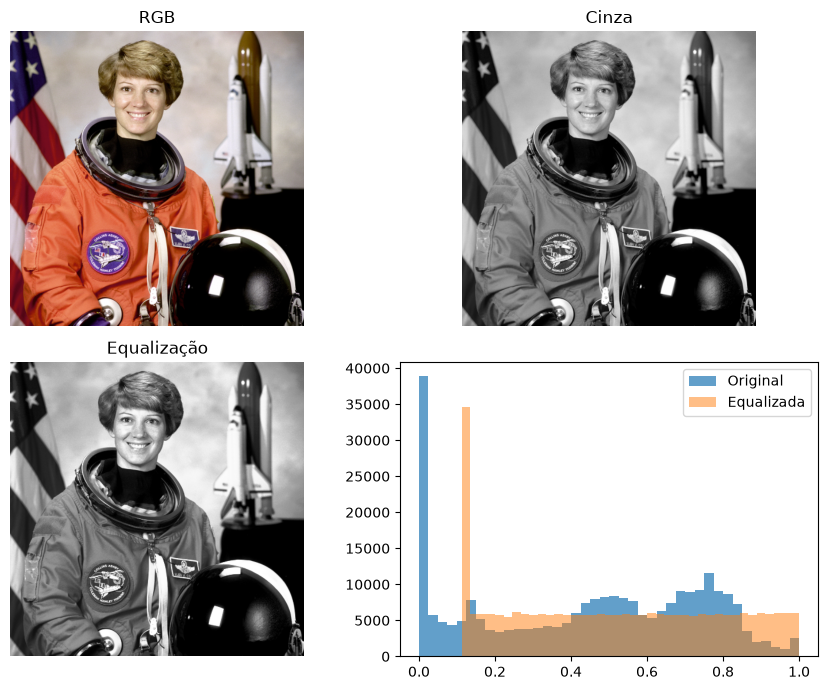

In [2]:
import matplotlib.pyplot as plt
fig,ax=plt.subplots(2,2,figsize=(9,7))
ax[0,0].imshow(rgb);ax[0,0].set_title('RGB')
ax[0,1].imshow(gray,cmap='gray');ax[0,1].set_title('Cinza')
ax[1,0].imshow(eq,cmap='gray');ax[1,0].set_title('Equalização')
ax[1,1].hist(gray.ravel(),bins=40,alpha=.7,label='Original');ax[1,1].hist(eq.ravel(),bins=40,alpha=.5,label='Equalizada');ax[1,1].legend()
for a in ax.flat[:3]:a.axis('off')
plt.tight_layout();plt.show()

## Interpretação técnica

Compare distribuição de intensidades e estruturas visíveis: uma imagem visualmente contrastada não é necessariamente melhor para reconhecimento.

### Conexão com o acervo

Em vez de repetir capítulos de SVM, PCA, métricas e backpropagation, este notebook concentra a aplicação e limitações **em imagens**. Revisite as Disciplinas 05 e 07 para demonstrações matemáticas mais extensas.

## Exercício resolvido

**Problema:** Dois arranjos diferentes de pixels podem ter o mesmo histograma?

**Resolução comentada:** Sim. Histogramas não codificam a localização dos pixels.

**Para praticar:** modifique um parâmetro do exemplo, registre a hipótese antes de executar e compare resultado, qualidade visual e custo computacional.

## Erros comuns e limitações

Lembre que a conversão BGR↔RGB é essencial ao combinar OpenCV e Matplotlib.

- Nunca ajustar parâmetros em cima do conjunto de teste final.
- Não confundir demonstração com validação científica completa.
- Documentar versões, fontes de dados e condições de execução.
- Não redistribuir fotografias de rostos ou datasets históricos sem licença e autorização.

## Consulta rápida

- **Pergunta-chave:** Comparar RGB, HSV e intensidade; avaliar equalização de histograma.
- **Mecanismo:** Os canais RGB codificam componentes de luz; HSV organiza matiz e saturação de maneira diferente.
- **Equação:** $h(k)=\sum_{x,y}{\bf1}[I(x,y)=k]$
- **Verificação:** interpretar formato dos dados, hipótese e saída antes de utilizar em um projeto.

### Referências de estudo

- Apresentações originais da disciplina (PDF consolidado).
- Documentação: [scikit-image](https://scikit-image.org/docs/stable/), [OpenCV](https://docs.opencv.org/4.x/), [scikit-learn](https://scikit-learn.org/stable/), conforme o capítulo.
- Para CNNs: [Keras](https://keras.io/).

## Aprofundamento v2 — auditoria e aplicação

**Ponto de atenção deste capítulo:** histograma e escala. Este complemento não substitui as seções e exemplos anteriores.

**Verificação conceitual.** Explique, com suas palavras, em qual etapa do fluxo de trabalho o tema **histograma e escala** pode produzir conclusões enganosas. Indique um indicador observável, um teste mínimo e uma limitação do procedimento.

**Exercício de extensão.** Reproduza o experimento central deste notebook alterando **um parâmetro por vez**. Compare com uma linha de base simples, reporte a variação da métrica pertinente e justifique o resultado. Quando houver treino/teste, qualquer etapa que aprenda parâmetros deve usar apenas o treino.

**Checklist de conclusão:** (1) entradas identificadas; (2) sementes registradas; (3) saídas interpretadas; (4) premissas explicitadas; (5) dados originais não sobrescritos.


### Laboratório adicional — Contraste e histograma quantizado

Experimento independente do estado das células anteriores. Use-o como verificação e explique seus limites; resultados em conjuntos sintéticos não são estimativas de desempenho real.

In [3]:
import numpy as np
img=np.array([[0,0,15],[30,127,255],[40,127,255]],dtype=np.uint8)
h,_=np.histogram(img,bins=4,range=(0,256))
print('Histograma em quatro bins:',h.tolist(),'pixels:',img.size)
assert h.sum()==img.size

Histograma em quatro bins: [5, 2, 0, 2] pixels: 9


### Exercício resolvido — protocolo mínimo de validação

**Enunciado.** Proponha uma comparação para **histograma e escala** sem contaminar a avaliação.

**Solução orientadora.** Defina uma hipótese falsificável, escolha um baseline simples, fixe uma divisão adequada ao problema, altere uma única decisão metodológica e compare métricas no conjunto reservado. Não transforme exemplos sintéticos em conclusões sobre populações reais. Documente a configuração e os casos de falha. Quando o tema não envolver predição, substitua o baseline por uma implementação de referência e compare correção, cobertura e custo.
